# Settings and utilities

## Plot settings and data paths

In [ ]:
import matplotlib.pyplot as plt
from google.colab import drive
from pathlib import Path

# Set common plot font sizes
plt.rcParams.update(
    {
        "font.size": 16,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 18,
    }
)

# Mount Google Drive and set the dataset root
# Change DATA_ROOT here if the practice folder is renamed or moved
drive.mount("/content/drive")
DATA_ROOT = Path("/content/drive/MyDrive/PHM Practice/Datasets")
PROJECT_ROOT = DATA_ROOT.parent

Mounted at /content/drive


## Shared utility functions

In [ ]:
import numpy as np
import pandas as pd

# Purpose: format displayed numbers without changing their stored values.
# Input: value (number); spec (optional standard Python format).
# Output: formatted text; the input value remains unchanged.
# Used in: Ch-2 fusion model: full data; Ch-2 fusion model: 10% data; Ch-2 embed-only model: full
# data; Ch-2 embed-only model: 10% data; MLP with one cycle sensor: full data; MLP with one cycle
# sensor: 10% data.
def format_number(value, spec=""):
    import numbers

    if not isinstance(value, numbers.Real):
        return format(value, spec)
    value = float(value)
    if spec.endswith(("e", "E", "g", "G", "%")):
        return format(value, spec)
    if 0 < abs(value) < 0.001:
        return f"{value:.3e}"
    precision = 3 if abs(value) < 10 else 2
    import re

    pattern = re.sub(r"\.\d+f$", f".{precision}f", spec) if spec else f".{precision}f"
    return format(value, pattern)

# Purpose: report model layers, parameter counts, and subset sizes.
# Input: model (Keras/PyTorch model), training/validation inputs, optional test.
# Output: printed model structure, parameter counts, and data shapes.
# Used in: Ch-2 fusion model: full data; Ch-2 fusion model: 10% data; Ch-2 embed-only model: full
# data; Ch-2 embed-only model: 10% data; MLP with one cycle sensor: full data; MLP with one cycle
# sensor: 10% data.
def show_model_info(model, training, validation, test=None):
    # Purpose: return the shapes of one or more model inputs.
    # Input: data.
    # Output: returned [tuple(value.shape) for value in values].
    def sample_shape(data):
        values = data if isinstance(data, (list, tuple)) else [data]
        return [tuple(value.shape) for value in values]

    # Purpose: return the number of samples in the model inputs.
    # Input: data.
    # Output: returned len(value).
    def sample_count(data):
        value = data[0] if isinstance(data, (list, tuple)) else data
        return len(value)

    print("Model structure")
    if hasattr(model, "summary"):
        model.summary()
        import numpy as np

        trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
        total = model.count_params()
    else:
        print(model)
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parameters: {total:,} total; {trainable:,} trainable")
    print(f"Training samples: {sample_count(training):,}")
    print(f"Validation samples: {sample_count(validation):,}")
    print("Training input shapes:", sample_shape(training))
    print("Validation input shapes:", sample_shape(validation))
    if test is not None:
        print(f"Test samples: {sample_count(test):,}")
        print("Test input shapes:", sample_shape(test))

# Purpose: create a callback that reports training and validation losses.
# Input: every (epoch interval, default 100).
# Output: Keras callback for progress reporting.
# Used in: Ch-2 fusion model: full data; Ch-2 fusion model: 10% data; Ch-2 embed-only model: full
# data; Ch-2 embed-only model: 10% data; MLP with one cycle sensor: full data; MLP with one cycle
# sensor: 10% data.
def training_progress(every=100):
    from tensorflow.keras.callbacks import LambdaCallback

    # Purpose: print training and validation loss at the selected epoch interval.
    # Input: epoch, logs.
    # Output: updated state or displayed result; no return value.
    def report(epoch, logs):
        if epoch == 0 or (epoch + 1) % every == 0:
            loss = format_number(logs.get("loss", float("nan")))
            valid = format_number(logs.get("val_loss", float("nan")))
            print(f"Epoch {epoch + 1}: training loss={loss}; validation loss={valid}")

    return LambdaCallback(on_epoch_end=report)

# Purpose: report completed epochs, best losses, and elapsed training time.
# Input: history (Keras history), started (time.perf_counter timestamp).
# Output: printed training summary.
# Used in: Ch-2 fusion model: full data; Ch-2 fusion model: 10% data; Ch-2 embed-only model: full
# data; Ch-2 embed-only model: 10% data; MLP with one cycle sensor: full data; MLP with one cycle
# sensor: 10% data.
def report_training(history, started):
    import time
    import numpy as np

    losses = history.history
    reference = losses.get("val_loss", losses["loss"])
    best = int(np.argmin(reference))
    print(f'Completed epochs: {len(losses["loss"])}; best epoch: {best + 1}')
    print("Best training loss:", format_number(losses["loss"][best]))
    if "val_loss" in losses:
        print("Best validation loss:", format_number(losses["val_loss"][best]))
    print("Training time:", format_number(time.perf_counter() - started), "s")

# Format displayed arrays and tables without modifying stored data
np.set_printoptions(formatter={"float_kind": format_number})
pd.options.display.float_format = format_number

# Purpose: apply 1-d Gaussian smoothing.
# Input: x, gauss_sigma, kernel_size.
# Output: returned y.
# Used in: C-MAPSS processing identical to chapter 8; Ch-2 fusion model: full data.
def gaussian_smooth_1d(x, gauss_sigma=1.0, kernel_size=5):

    x = np.asarray(x, dtype=float)

    if kernel_size % 2 == 0:
        raise ValueError("kernel_size must be an odd number.")

    half_kernel = kernel_size // 2

    # Data-point offsets around the current point
    k = np.arange(-half_kernel, half_kernel + 1)

    # Gaussian kernel weights
    kernel = np.exp(-(k**2) / (2 * gauss_sigma**2))
    kernel = kernel / np.sum(kernel)

    # Edge padding to keep the output length same as input length
    x_pad = np.pad(x, pad_width=half_kernel, mode="edge")

    # Weighted moving average using Gaussian kernel
    y = np.convolve(x_pad, kernel, mode="valid")

    return y

# Purpose: convert row-wise engine-cycle data into sequence data.
# Input: X_row, y_row, eng_num, cyc, window_length.
# Output: returned (X_seq, y_seq, eng_seq, cyc_seq).
# Used in: C-MAPSS processing identical to chapter 8; Ch-2 fusion model: full data.
def make_sequence_data_no_padding(X_row, y_row, eng_num, cyc, window_length=30):

    X_row = np.asarray(X_row)
    y_row = np.ravel(y_row)
    eng_num = np.ravel(eng_num)
    cyc = np.ravel(cyc)

    X_seq = []
    y_seq = []
    eng_seq = []
    cyc_seq = []

    engine_ids = np.unique(eng_num)

    for eid in engine_ids:

        idx = np.where(eng_num == eid)[0]

        # Sort by cycle
        idx = idx[np.argsort(cyc[idx])]

        X_e = X_row[idx, :]
        y_e = y_row[idx]
        cyc_e = cyc[idx]

        n_e = len(idx)

        # Start only when a full window is available
        for t in range(window_length - 1, n_e):

            start = t - window_length + 1

            window = X_e[start : t + 1, :]

            X_seq.append(window)
            y_seq.append(y_e[t])
            eng_seq.append(eid)
            cyc_seq.append(cyc_e[t])

    X_seq = np.asarray(X_seq)
    y_seq = np.asarray(y_seq)
    eng_seq = np.asarray(eng_seq)
    cyc_seq = np.asarray(cyc_seq)

    return X_seq, y_seq, eng_seq, cyc_seq

# Purpose: plot targets versus predictions with fitted line and R².
# Input: ax, y_true, y_pred, title.
# Output: updated state or displayed result; no return value.
# Used in: Ch-2 fusion model: full data.
def plot_regression_r2_subplot(ax, y_true, y_pred, title="Regression plot"):

    y_true = np.ravel(y_true)
    y_pred = np.ravel(y_pred)

    r2 = r2_score(y_true, y_pred)

    # Linear fit: y_pred = a*y_true + b
    a, b = np.polyfit(y_true, y_pred, 1)

    x_min = min(y_true.min(), y_pred.min())
    x_max = max(y_true.max(), y_pred.max())

    x_line = np.linspace(x_min, x_max, 100)
    y_fit = a * x_line + b

    ax.plot(y_true, y_pred, "o", markerfacecolor="none", markersize=4, label="Data")

    ax.plot(x_line, y_fit, linewidth=2, label="Fit")

    ax.plot(x_line, x_line, "k:", linewidth=1.5, label="Y = T")

    ax.set_xlabel("Target RUL"); ax.set_ylabel("Predicted RUL")

    ax.set_title(f"{title}\nR² = {format_number(r2, '.4f')}", fontsize=12)

    ax.grid(True); ax.legend(loc="upper left")

# C-MAPSS processing identical to chapter 8

This preprocessing block is reproduced from Chapter 8 so that this notebook can be executed independently. Sensor selection, normalization, smoothing, RUL definition, and sequence construction use the same procedures and settings as in Chapter 8.

### Import training data.

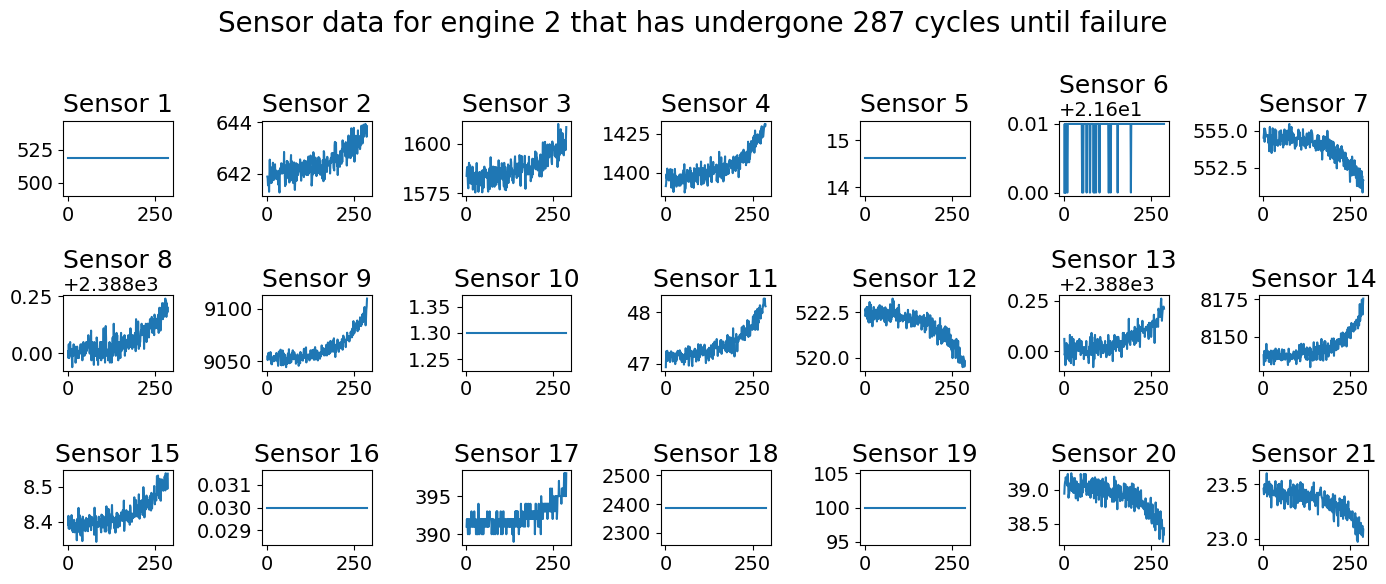

In [ ]:
# Select a C-MAPSS subset: uncomment one assignment only
dataName = 'FD001'
# dataName = 'FD003'

# Select the engine displayed in the example
ig = 2

import scipy.io as io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = DATA_ROOT / "CMAPSS"
file_path = data_dir / f"train_{dataName}.txt"

data = pd.read_csv(file_path, header=None, sep=r"\s+").values

# Data construction
eng_num = data[:, 0]  # Engine id
cyc = data[:, 1]  # Cycle
op = data[:, 2:5]  # Operating condition
sen = data[:, 5:26]  # Sensor data
eng, eng1 = np.unique(
    eng_num, return_index=True
)  # J includes 1st cycle in cumulative number of engine i
eng1 += 1
neng = len(eng)  # Number of engines to be used for training
ndata = len(data)  # Total number of data

plt.figure(figsize=(14, 6))  # Plot all the sensors data of engine #ig as an example
eol = int(cyc[eng_num == ig].max())

for i in range(21):
    plt.subplot(3, 7, i + 1)
    plt.plot(cyc[eng_num == ig], sen[eng_num == ig, i])
    plt.title("Sensor {}".format(i + 1))

plt.suptitle(
    "Sensor data for engine {} that has undergone {} cycles until failure".format(
        ig, eol
    ),
    fontsize=20,
)

plt.tight_layout(); plt.show()

### Sensor selection

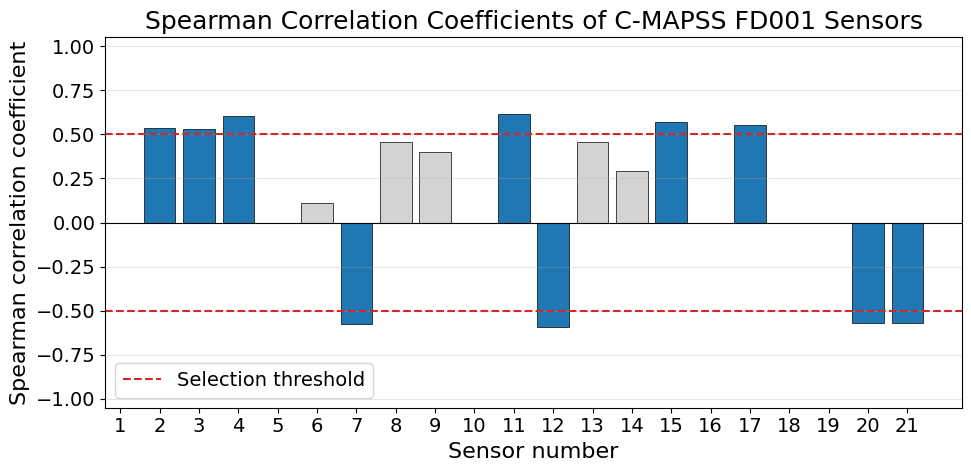

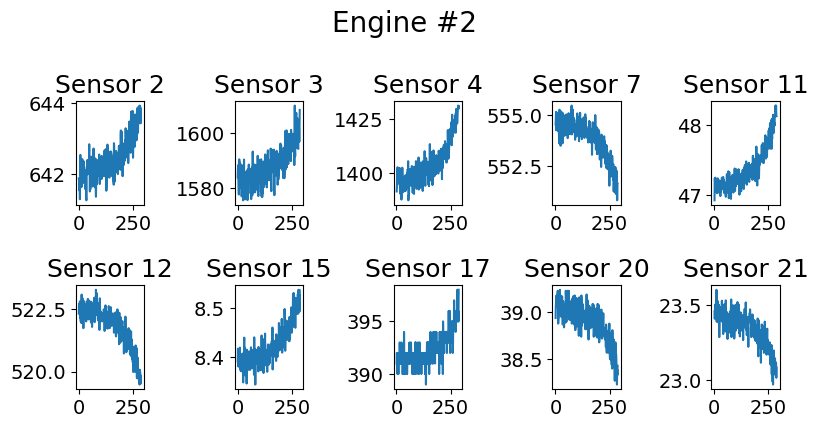

In [ ]:
# Preprocessing of training data

# Select sensors by Spearman correlation
cyc = np.reshape(cyc, (np.shape(cyc)[0], 1))
corrdata = pd.DataFrame(
    np.hstack([sen, cyc])
)  # 1~21 = Sen, 22 = cycselected sensors data
spval = np.array(corrdata.corr(method="spearman"))[-1, :-1]
selOrd = [i for (i, val) in enumerate(spval) if abs(val) > 0.5]
selSen = sen[:, selOrd]  # Selected sensors data

# Plot the pooled Spearman correlation of each sensor with cycle.
sensor_ids = np.arange(1, len(spval) + 1)
selected = np.abs(spval) > 0.5
colors = np.where(selected, "tab:blue", "lightgray")

plt.figure(figsize=(10, 5))
plt.bar(sensor_ids, spval, color=colors, edgecolor="black", linewidth=0.5)
plt.axhline(0.5, color="tab:red", linestyle="--", label="Selection threshold")
plt.axhline(-0.5, color="tab:red", linestyle="--")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(sensor_ids); plt.ylim(-1.05, 1.05); plt.xlabel("Sensor number")
plt.ylabel("Spearman correlation coefficient")
plt.title(f"Spearman Correlation Coefficients of C-MAPSS {dataName} Sensors")
plt.grid(axis="y", alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

# Plot selected sensors data of engine #ig
plt.figure(figsize=(8, 6))
for k in range(len(selOrd)):
    plt.subplot(3, 5, k + 1)
    ks = selOrd[k]
    plt.plot(cyc[eng_num == ig], selSen[eng_num == ig, k])
    plt.title("Sensor {}".format(ks + 1))
plt.suptitle("Engine #{}".format(ig), fontsize=20)
plt.tight_layout(); plt.show()

### Sensor normalization

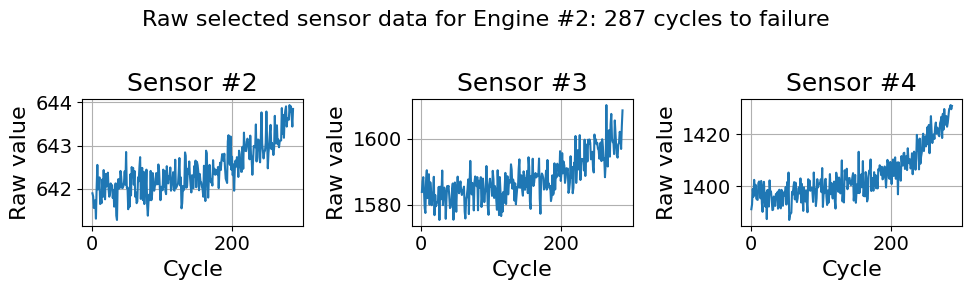

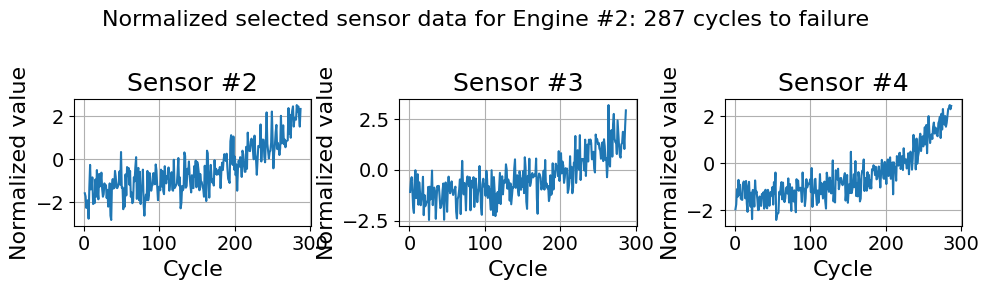

In [ ]:
# User settings: change these values to repeat the experiment
ig = 2  # Engine shown in the example plot

import numpy as np
import matplotlib.pyplot as plt

# Normalize selected sensors using all training engines

mu = np.mean(selSen, axis=0)
sigma = np.std(selSen, axis=0)

sigma_safe = sigma.copy()
sigma_safe[sigma_safe == 0] = 1

selSen0 = (selSen - mu) / sigma_safe

# Save training normalization parameters
mu_train = mu.copy()
sigma_train_safe = sigma_safe.copy()

# User settings

display_sensor_ids = [2, 3, 4]

# Convert display sensor numbers to positions inside selSen

display_pos = []
display_sid = []

for sid in display_sensor_ids:

    sidx = sid - 1

    if sidx in selOrd:
        display_pos.append(selOrd.index(sidx))
        display_sid.append(sid)
    else:
        print(f"Sensor #{sid} was not selected and will be skipped.")

# Extract selected engine data

idx = eng_num == ig

cyc_e = np.ravel(cyc[idx])

selSen_e = selSen[idx, :]
selSen0_e = selSen0[idx, :]

eol = int(cyc_e.max())

# Figure 1: raw selected sensor signals

plt.figure(figsize=(10, 3))

for k, pos in enumerate(display_pos):

    sid = display_sid[k]

    plt.subplot(1, len(display_pos), k + 1)
    plt.plot(cyc_e, selSen_e[:, pos])
    plt.title(f"Sensor #{sid}")
    plt.xlabel("Cycle"); plt.ylabel("Raw value"); plt.grid(True)

plt.suptitle(
    f"Raw selected sensor data for Engine #{ig}: {eol} cycles to failure", fontsize=16
)

plt.tight_layout(); plt.show()

# Figure 2: normalized selected sensor signals

plt.figure(figsize=(10, 3))

for k, pos in enumerate(display_pos):

    sid = display_sid[k]

    plt.subplot(1, len(display_pos), k + 1)
    plt.plot(cyc_e, selSen0_e[:, pos])
    plt.title(f"Sensor #{sid}")
    plt.xlabel("Cycle"); plt.ylabel("Normalized value"); plt.grid(True)

plt.suptitle(
    f"Normalized selected sensor data for Engine #{ig}: {eol} cycles to failure",
    fontsize=16,
)

plt.tight_layout(); plt.show()

### Sensor smoothing

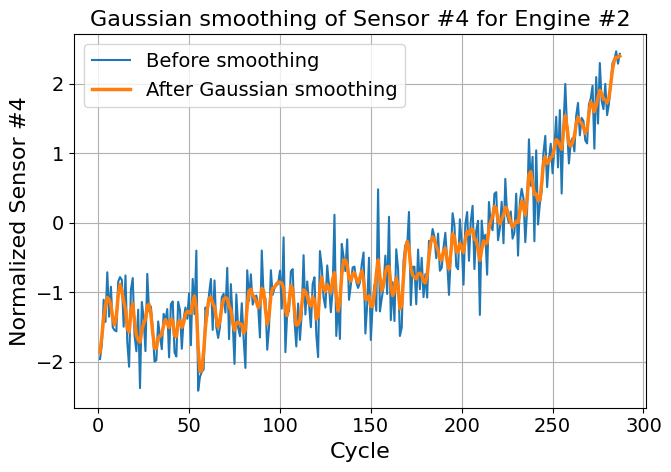

In [ ]:
# User settings: change these values to repeat the experiment
gauss_sigma = 1.0  # Width of the Gaussian kernel
kernel_size = 5  # Total number of data points in the Gaussian kernel
ig = 2  # Engine id to display
display_sensor_id = 4  # Actual sensor number, not Python index

import numpy as np
import matplotlib.pyplot as plt

# User settings

# Must be an odd number

# Gaussian smoothing function

# Apply Gaussian smoothing to selected and normalized sensors
# Engine by engine

selSen_smooth = np.zeros_like(selSen0)

for eid in np.unique(eng_num):

    idx_e = eng_num == eid

    for j in range(selSen0.shape[1]):

        selSen_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen0[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

# Plot before and after smoothing

display_sensor_index = display_sensor_id - 1

if display_sensor_index not in selOrd:
    raise ValueError(
        f"Sensor #{display_sensor_id} was not selected by Spearman correlation."
    )

# Position of the displayed sensor inside selSen0
k_display = selOrd.index(display_sensor_index)

idx_display = eng_num == ig

cyc_e = np.ravel(cyc[idx_display])

y_before = selSen0[idx_display, k_display]
y_after = selSen_smooth[idx_display, k_display]

eol = int(cyc_e.max())

plt.figure(figsize=(7, 5))

plt.plot(cyc_e, y_before, label="Before smoothing", linewidth=1.5)

plt.plot(cyc_e, y_after, label="After Gaussian smoothing", linewidth=2.5)

plt.xlabel("Cycle")
plt.ylabel(f"Normalized Sensor #{display_sensor_id}")

plt.title(
    f"Gaussian smoothing of Sensor #{display_sensor_id} for Engine #{ig}", fontsize=16
)

plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

### RUL definition

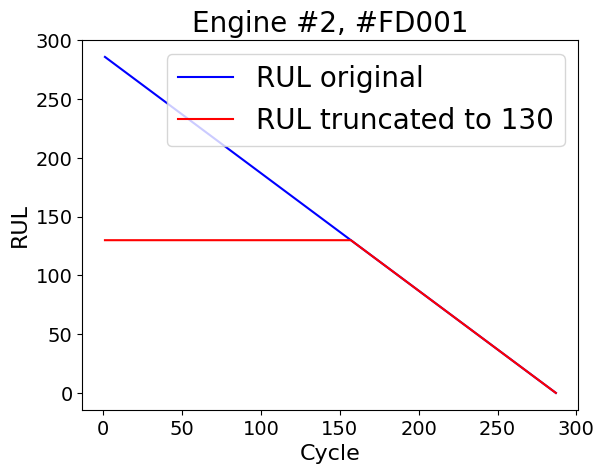

In [ ]:
# Define RUL such that it decreases from (eol-1) at 1st to 0 at EOL.
rul = np.concatenate(
    [-cyc[eng_num == i] + np.max(cyc[eng_num == i]) for i in range(1, neng + 1)]
)

plt.figure()  # Plot rul original of engine #ig.
plt.plot(cyc[eng_num == ig], rul[eng_num == ig], "b")

EOL = np.concatenate((np.diff(eng1), ndata - np.max(eng1)), axis=None)
EOLmin = np.min(EOL)
cmin = round(EOLmin / 10) * 10  # Minimum rul rounded to order of 10.
rul = np.where(cmin < rul, cmin, rul)  # Truncate rul at cmin.

plt.plot(cyc[eng_num == ig], rul[eng_num == ig], "r")
plt.legend(["RUL original", f"RUL truncated to {cmin}"], fontsize=20); plt.ylabel("RUL")
plt.xlabel("Cycle")
plt.title(f"Engine #{ig}, #{dataName}", fontsize=20)
plt.show()

# Ch-2 fusion model: full data

### Ch-2 install and import

In [ ]:
# Install Chronos-2 for Google Colab

!pip install -q "chronos-forecasting>=2.1.0" jedi

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import tensorflow as tf

from chronos import Chronos2Pipeline
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import AdamW
from tqdm.auto import tqdm

try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
except RuntimeError:
    pass

print("Chronos-2 import successful")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.6/80.6 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 110.6 MB/s eta 0:00:00
Chronos-2 import successful


### Prepare sequence data

In [ ]:
# User settings: change these values to repeat the experiment
window_length = 30  # Cycles in each complete input window

# Prepare sequence data using the chapter 8 definition

model_type = "Chronos2_EmbeddingSensorFusion"
model_label = "Chronos-2 embedding-sensor fusion model"

X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data_no_padding(
    selSen_smooth, rul, eng_num, cyc, window_length=window_length
)

X_seq = np.asarray(X_seq, dtype=np.float32)
y_seq = np.asarray(y_seq, dtype=np.float32).ravel()
eng_seq = np.asarray(eng_seq)
cyc_seq = np.asarray(cyc_seq)

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)
print("eng_seq shape:", eng_seq.shape)
print("cyc_seq shape:", cyc_seq.shape)

X_seq shape: (17731, 30, 10)
y_seq shape: (17731,)
eng_seq shape: (17731,)
cyc_seq shape: (17731,)


### Load frozen Ch-2

In [ ]:
# Load frozen Chronos-2

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is required. In Colab, select Runtime > Change runtime type > T4 GPU, then"
        " run again."
    )

device = "cuda"
chronos_model_name = "amazon/chronos-2"

tsfm_model = Chronos2Pipeline.from_pretrained(chronos_model_name, device_map=device)

num_params = sum(p.numel() for p in tsfm_model.model.parameters())
for param in tsfm_model.model.parameters():
    param.requires_grad = False
tsfm_model.model.eval()

print("Loaded TSFM:", chronos_model_name)
print("Device:", tsfm_model.model.device)
print(f"Number of TSFM parameters: {num_params:,}")
print("TSFM is frozen:", not any(p.requires_grad for p in tsfm_model.model.parameters()))

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded TSFM: amazon/chronos-2
Device: cuda:0
Number of TSFM parameters: 119,477,664
TSFM is frozen: True


### Create or load Ch-2 embeddings

In [ ]:
# Function: extract Ch-2 embeddings

# Extract the last encoder embedding for every sensor
# Input:  (samples, window, sensors)
# Output: (samples, sensors, embedding dimension)

# Purpose: extract Chronos embeddings.
# Input: pipeline, X, batch_size.
# Output: returned np.stack(output).astype(np.float32).
# Used in: Ch-2 fusion model: full data.
def extract_chronos_embeddings(pipeline, X, batch_size=256):
    X_chronos = np.transpose(np.asarray(X, dtype=np.float32), (0, 2, 1))
    output = []

    for start in tqdm(range(0, len(X_chronos), batch_size)):
        batch = X_chronos[start : start + batch_size]
        embeddings, _ = pipeline.embed(
            batch, batch_size=batch_size, context_length=batch.shape[-1]
        )
        output.extend(e[:, -1, :].float().numpy() for e in embeddings)

    return np.stack(output).astype(np.float32)

In [ ]:
# Generate or load training embeddings
# Embeddings are reused for the full-data and 10-engine runs.

# Select embedding-cache use: uncomment one assignment only
use_embedding_cache = True
# use_embedding_cache = False
# Cache filenames distinguish datasets; disable reuse after changing preprocessing
chronos_embedding_batch_size = 256
cache_dir = data_dir
os.makedirs(cache_dir, exist_ok=True)

chronos_short_name = chronos_model_name.split("/")[-1]
sensor_tag = "-".join(str(i + 1) for i in selOrd)
embedding_cache_file = os.path.join(
    cache_dir, f"Z_seq_{dataName}_{chronos_short_name}_W{window_length}_S{sensor_tag}.npy"
)

if use_embedding_cache and os.path.exists(embedding_cache_file):
    print("Loading cached embeddings:")
    print(embedding_cache_file)
    Z_seq = np.load(embedding_cache_file)
else:
    start_time = time.perf_counter()
    Z_seq = extract_chronos_embeddings(
        tsfm_model, X_seq, batch_size=chronos_embedding_batch_size
    )
    print(
        "Embedding extraction time:"
        f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
    )
    if use_embedding_cache:
        np.save(embedding_cache_file, Z_seq)
        print("Saved embeddings to:")
        print(embedding_cache_file)

X_current_sensors = X_seq[:, -1, :].astype(np.float32)
print("Z_seq shape:", Z_seq.shape)
print("X_current_sensors shape:", X_current_sensors.shape)

Loading cached embeddings:
/content/drive/MyDrive/PHM Practice/Datasets/CMAPSS/Z_seq_chronos-2_W30_S2-3-4-7-11-12-15-17-20-21.npy
Z_seq shape: (17731, 10, 768)
X_current_sensors shape: (17731, 10)


### Functions

In [ ]:
# User settings: change these values to repeat the experiment
compression_units = 8
hidden_units = (256, 64)
dropout_rate = 0.2
learning_rate = 1e-4  # Optimizer learning rate
weight_decay = 1e-3
batch_size = 1024  # Samples per training batch
max_epochs = 500  # 150
patience = 15  # Epochs without validation improvement

# Central head settings
# Change values only here.

# Purpose: build the Chronos embedding and current-sensor fusion head.
# Input: n_sensors, embedding_dim.
# Output: returned model.
# Used in: Ch-2 fusion model: full data; Ch-2 fusion model: 10% data.
def build_chronos_head(n_sensors, embedding_dim):
    embedding_input = tf.keras.Input(
        shape=(n_sensors, embedding_dim), name="chronos_embeddings"
    )
    sensor_input = tf.keras.Input(shape=(n_sensors,), name="current_sensors")

    compressed_embeddings = tf.keras.layers.Dense(
        compression_units, activation=tf.nn.gelu, name="shared_compression"
    )(embedding_input)
    compressed_embeddings = tf.keras.layers.Flatten(name="compress_and_flatten")(
        compressed_embeddings
    )
    x = tf.keras.layers.Concatenate(name="embedding_sensor_fusion")(
        [compressed_embeddings, sensor_input]
    )

    for units in hidden_units:
        x = tf.keras.layers.Dense(units, activation=tf.nn.gelu)(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    output = tf.keras.layers.Dense(1, name="rul")(x)
    model = tf.keras.Model([embedding_input, sensor_input], output)
    model.compile(
        optimizer=AdamW(learning_rate=learning_rate, weight_decay=weight_decay),
        loss="mse",
        metrics=["mse"],
    )
    return model

### Reg head training by enginewise split

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
random_state = 0  # Random seed for reproducible splitting

import time

# Set the epoch reporting interval

# Full development data: same engine-wise split as chapter 8

engine_ids = np.unique(eng_seq)
train_engines, valid_engines = train_test_split(
    engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=random_state
)

idx_train = np.isin(eng_seq, train_engines)
idx_valid = np.isin(eng_seq, valid_engines)

Z_train, Z_valid = Z_seq[idx_train], Z_seq[idx_valid]
X_train_sensors, X_valid_sensors = (
    X_current_sensors[idx_train],
    X_current_sensors[idx_valid],
)
y_train_seq, y_valid_seq = y_seq[idx_train], y_seq[idx_valid]

print("Number of train engines:", len(train_engines))
print("Number of validation engines:", len(valid_engines))
print("Z_train shape:", Z_train.shape)
print("Z_valid shape:", Z_valid.shape)

# Train the Chronos-2 embedding-sensor fusion head

tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()

model_chronos = build_chronos_head(Z_seq.shape[1], Z_seq.shape[2])
early_stopping = EarlyStopping(
    monitor="val_loss", patience=patience, restore_best_weights=True
)

start_time = time.perf_counter()
# Report the model and data before training
show_model_info(model_chronos, [Z_train, X_train_sensors], [Z_valid, X_valid_sensors])
training_started = time.perf_counter()
history = model_chronos.fit(
    [Z_train, X_train_sensors],
    y_train_seq,
    batch_size=batch_size,
    epochs=max_epochs,
    validation_data=([Z_valid, X_valid_sensors], y_valid_seq),
    callbacks=[early_stopping] + [training_progress(progress_interval)],
    verbose=0,
)
report_training(history, training_started)
print(
    "Training time of Embedding-sensor fusion head:"
    f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
)

Number of train engines: 75
Number of validation engines: 25
Z_train shape: (13236, 10, 768)
Z_valid shape: (4495, 10, 768)
Training time of Embedding-sensor fusion head: 2.80 min


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chronos_embeddings  │ (None, 10, 768)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_compression  │ (None, 10, 8)     │      6,152 │ chronos_embeddin… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ compress_and_flatt… │ (None, 80)        │          0 │ shared_compressi… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ current_sensors     │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_sensor_f… │ (None, 90)        │          0 │ compress_and_fla… │
│ (Concatenate)       │                   │            │ current_sensors[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     23,296 │ embedding_sensor… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rul (Dense)         │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 137,885 (538.62 KB)

 Trainable params: 45,961 (179.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 91,924 (359.08 KB)

### Plot training val loss & R2

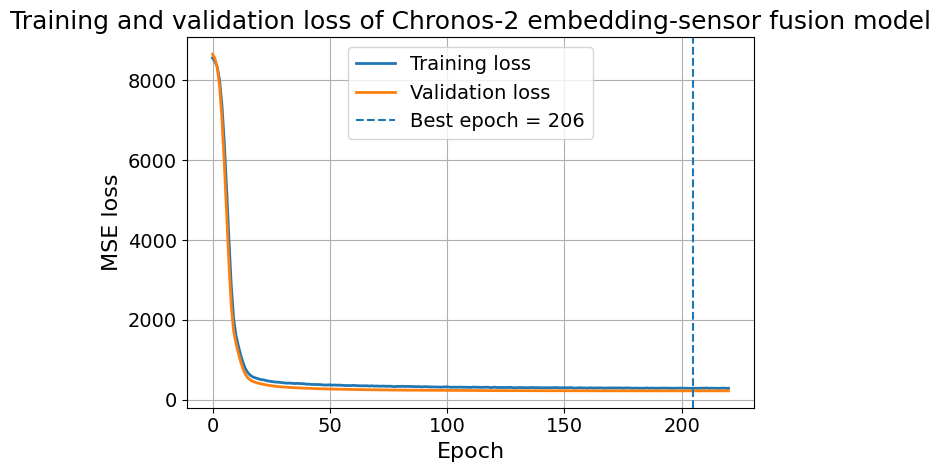

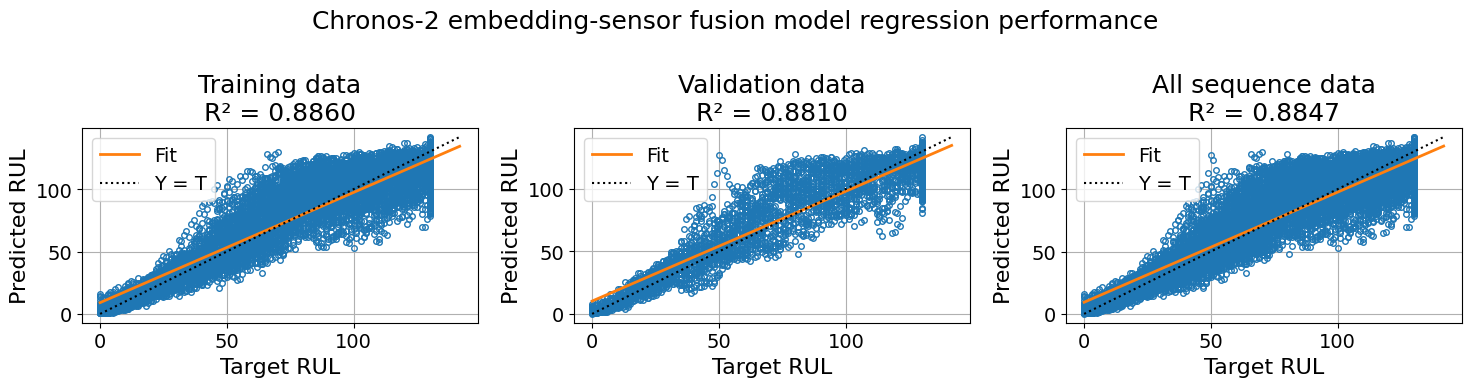

Chronos2_EmbeddingSensorFusion
  Training RMSE   = 14.6378
  Validation RMSE = 14.9502
  All-data RMSE   = 14.7177


In [ ]:
# Loss, R2 plots, and development-data RMSE

train_loss = history.history["loss"]
valid_loss = history.history["val_loss"]
best_epoch = np.argmin(valid_loss) + 1

plt.figure(figsize=(7, 5))
plt.plot(train_loss, label="Training loss", linewidth=2)
plt.plot(valid_loss, label="Validation loss", linewidth=2)
plt.axvline(
    best_epoch - 1, linestyle="--", linewidth=1.5, label=f"Best epoch = {best_epoch}"
)
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title(f"Training and validation loss of {model_label}"); plt.grid(True); plt.legend()
plt.tight_layout(); plt.show()

y_train_pred = model_chronos.predict([Z_train, X_train_sensors], verbose=0).ravel()
y_valid_pred = model_chronos.predict([Z_valid, X_valid_sensors], verbose=0).ravel()
y_all_pred = model_chronos.predict([Z_seq, X_current_sensors], verbose=0).ravel()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_regression_r2_subplot(axes[0], y_train_seq, y_train_pred, "Training data")
plot_regression_r2_subplot(axes[1], y_valid_seq, y_valid_pred, "Validation data")
plot_regression_r2_subplot(axes[2], y_seq, y_all_pred, "All sequence data")
plt.suptitle(f"{model_label} regression performance")
plt.tight_layout(); plt.show()

print(model_type)
print(
    "  Training RMSE   ="
    f" {format_number(np.sqrt(mean_squared_error(y_train_seq, y_train_pred)), '.4f')}"
)
print(
    "  Validation RMSE ="
    f" {format_number(np.sqrt(mean_squared_error(y_valid_seq, y_valid_pred)), '.4f')}"
)
print(
    "  All-data RMSE   ="
    f" {format_number(np.sqrt(mean_squared_error(y_seq, y_all_pred)), '.4f')}"
)

### Predict RUL for training

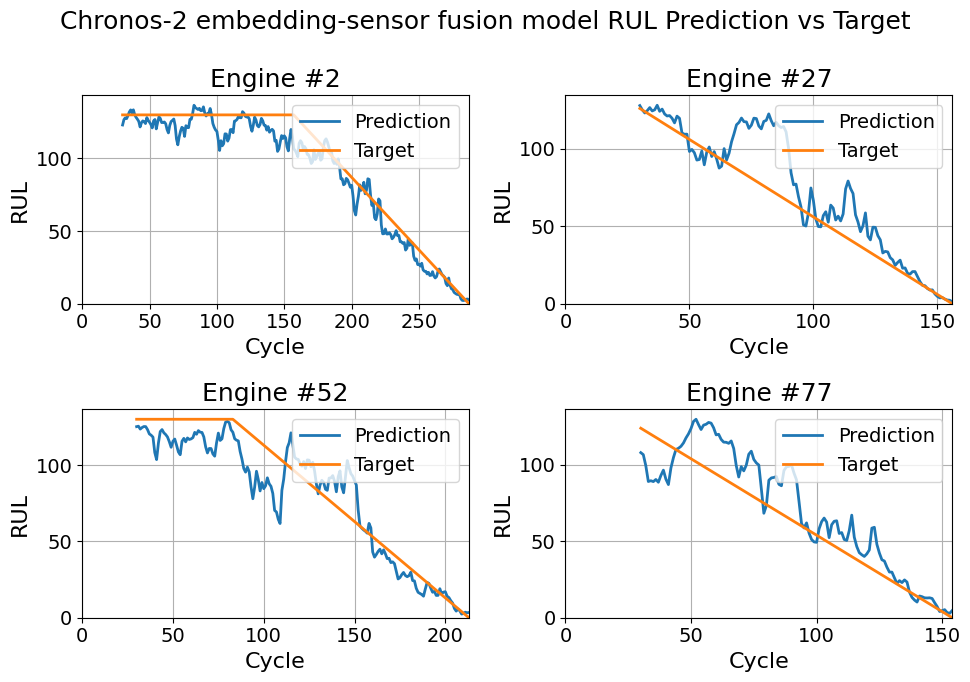

In [ ]:
# Plot RUL prediction for selected training engines

display_engines = [2, 27, 52, 77]
plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):
    idx = eng_seq == eid
    order = np.argsort(cyc_seq[idx])
    cyc_e, y_true_e = cyc_seq[idx][order], y_seq[idx][order]
    y_pred_e = model_chronos.predict(
        [Z_seq[idx][order], X_current_sensors[idx][order]], verbose=0
    ).ravel()
    plt.subplot(2, 2, ii)
    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)
    plt.plot(cyc_e, y_true_e, label="Target", linewidth=2)
    plt.title(f"Engine #{int(eid)}")
    plt.xlabel("Cycle"); plt.ylabel("RUL"); plt.xlim(0, int(cyc_e.max()))
    plt.ylim(bottom=0); plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(f"{model_label} RUL Prediction vs Target")
plt.tight_layout(); plt.show()

### Load and process test set

In [ ]:
# Use the C-MAPSS subset selected in the training-data cell
# Load the matching official test set

data_dir = DATA_ROOT / "CMAPSS"
test_data = pd.read_csv(data_dir / f"test_{dataName}.txt", header=None, sep=r"\s+").values
true_rul_final = pd.read_csv(
    data_dir / f"RUL_{dataName}.txt", header=None, sep=r"\s+"
).values.ravel()

eng_num_test, cyc_test = test_data[:, 0], test_data[:, 1]
sen_test = test_data[:, 5:26]
engine_ids_test = np.unique(eng_num_test)

selSen_test = sen_test[:, selOrd]
selSen_test_norm = (selSen_test - mu_train) / sigma_train_safe
selSen_test_smooth = np.zeros_like(selSen_test_norm)

for eid in engine_ids_test:
    idx_e = eng_num_test == eid
    for j in range(selSen_test_norm.shape[1]):
        selSen_test_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen_test_norm[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

print("test_data shape:", test_data.shape)
print("selSen_test_smooth shape:", selSen_test_smooth.shape)
print("true_rul_final shape:", true_rul_final.shape)

test_data shape: (13096, 26)
selSen_test_smooth shape: (13096, 10)
true_rul_final shape: (100,)


### Predict RUL for test

Loading cached final test embeddings:
/content/drive/MyDrive/PHM Practice/Datasets/CMAPSS/Z_test_final_chronos-2_W30_S2-3-4-7-11-12-15-17-20-21.npy
Z_test_final shape: (100, 10, 768)
pred_rul_final shape: (100,)
FD001 final-cycle test RMSE of Chronos2_EmbeddingSensorFusion = 16.3813
FD001 final-cycle test Score of Chronos2_EmbeddingSensorFusion = 568.3001
Loading cached four-engine test embeddings: /content/drive/MyDrive/PHM Practice/Datasets/CMAPSS/Z_test_curves_chronos-2_W30_S2-3-4-7-11-12-15-17-20-21_E2-27-52-77.npy


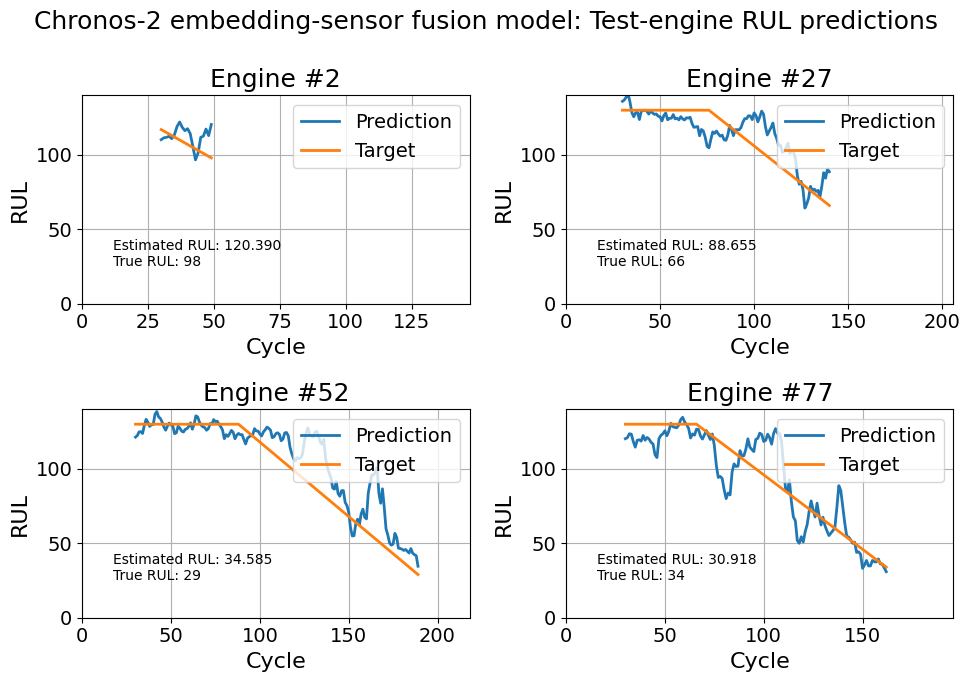

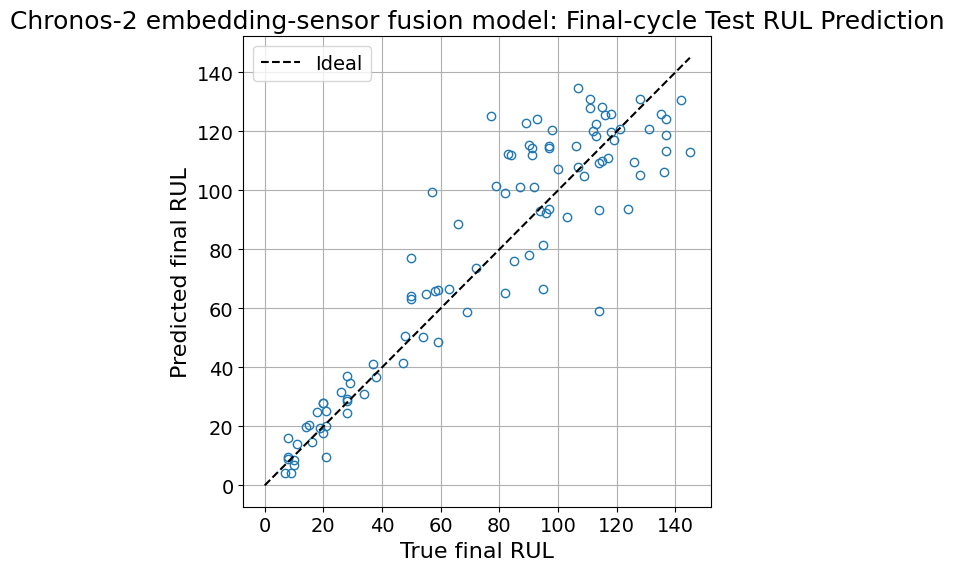

In [ ]:
# Final-cycle test evaluation

X_test_final = []
for eid in engine_ids_test:
    idx_e = np.where(eng_num_test == eid)[0]
    idx_e = idx_e[np.argsort(cyc_test[idx_e])]
    X_e = selSen_test_smooth[idx_e]
    if len(X_e) < window_length:
        raise ValueError(f"Engine {eid} is shorter than window_length.")
    X_test_final.append(X_e[-window_length:])

X_test_final = np.asarray(X_test_final, dtype=np.float32)
X_test_sensors = X_test_final[:, -1, :]
test_cache_file = os.path.join(
    cache_dir, f"Z_test_final_{dataName}_{chronos_short_name}_W{window_length}_S{sensor_tag}.npy"
)

if use_embedding_cache and os.path.exists(test_cache_file):
    print("Loading cached final test embeddings:")
    print(test_cache_file)
    Z_test_final = np.load(test_cache_file)
else:
    start_time = time.perf_counter()
    Z_test_final = extract_chronos_embeddings(
        tsfm_model, X_test_final, batch_size=chronos_embedding_batch_size
    )
    print(
        "Final test embedding extraction time:"
        f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
    )
    if use_embedding_cache:
        np.save(test_cache_file, Z_test_final)

# Purpose: CMAPSS metrics.
# Input: y_true, y_pred.
# Output: returned (rmse, score).
# Used in: Ch-2 fusion model: 10% data; Ch-2 embed-only model: full data; Ch-2 embed-only model: 10%
# data; MLP with one cycle sensor: full data; MLP with one cycle sensor: 10% data.
def cmapss_metrics(y_true, y_pred):
    errors = np.ravel(y_pred) - np.ravel(y_true)
    rmse = np.sqrt(np.mean(errors**2))
    score = np.sum(
        np.where(errors < 0, np.exp(-errors / 13.0) - 1.0, np.exp(errors / 10.0) - 1.0)
    )
    return rmse, score

pred_rul_final = model_chronos.predict([Z_test_final, X_test_sensors], verbose=0).ravel()
rmse_test, score_test = cmapss_metrics(true_rul_final, pred_rul_final)

print("Z_test_final shape:", Z_test_final.shape)
print("pred_rul_final shape:", pred_rul_final.shape)
print(f"{dataName} final-cycle test RMSE of {model_type} = {format_number(rmse_test, '.4f')}")
print(
    f"{dataName} final-cycle test Score of {model_type} = {format_number(score_test, '.4f')}"
)

# RUL trajectories for the same four test engines used in chapter 8
display_engines = [2, 27, 52, 77]
X_test_curves, curve_cycles, curve_targets, curve_engine_ids = [], [], [], []
for eid in display_engines:
    idx = np.where(eng_num_test == eid)[0]
    idx = idx[np.argsort(cyc_test[idx])]
    final_target = true_rul_final[np.flatnonzero(engine_ids_test == eid)[0]]
    last_cycle = cyc_test[idx[-1]]
    for end in range(window_length - 1, len(idx)):
        X_test_curves.append(selSen_test_smooth[idx[end - window_length + 1 : end + 1]])
        curve_cycles.append(cyc_test[idx[end]])
        curve_targets.append(min(cmin, final_target + last_cycle - cyc_test[idx[end]]))
        curve_engine_ids.append(eid)

X_test_curves = np.asarray(X_test_curves, dtype=np.float32)
curve_cycles = np.asarray(curve_cycles)
curve_targets = np.asarray(curve_targets)
curve_engine_ids = np.asarray(curve_engine_ids)
curve_cache_file = os.path.join(
    cache_dir,
    f"Z_test_curves_{dataName}_{chronos_short_name}_W{window_length}_S{sensor_tag}_E2-27-52-77.npy",
)
if use_embedding_cache and os.path.exists(curve_cache_file):
    Z_test_curves = np.load(curve_cache_file)
    if Z_test_curves.shape != (len(X_test_curves), len(selOrd), Z_seq.shape[-1]):
        raise ValueError("Curve embedding cache shape mismatch. Regenerate this cache.")
    print("Loading cached four-engine test embeddings:", curve_cache_file)
else:
    extraction_start = time.perf_counter()
    Z_test_curves = extract_chronos_embeddings(
        tsfm_model, X_test_curves, batch_size=chronos_embedding_batch_size
    )
    print(
        "Four-engine embedding extraction time:"
        f" {format_number((time.perf_counter() - extraction_start) / 60, '.2f')} min"
    )
    if use_embedding_cache:
        np.save(curve_cache_file, Z_test_curves)

pred_test_curves = model_chronos.predict(
    [Z_test_curves, X_test_curves[:, -1, :]], verbose=0
).ravel()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, eid in zip(axes.ravel(), display_engines):
    mask = curve_engine_ids == eid
    cycles_e = curve_cycles[mask]
    prediction_e = pred_test_curves[mask]
    epos = np.flatnonzero(engine_ids_test == eid)[0]
    # Use the same final prediction as the 100-engine test evaluation.
    prediction_e[-1] = pred_rul_final[epos]
    final_target = true_rul_final[epos]
    ax.plot(cycles_e, prediction_e, label="Prediction", linewidth=2)
    ax.plot(cycles_e, curve_targets[mask], label="Target", linewidth=2)
    ax.set(
        title=f"Engine #{eid}",
        xlabel="Cycle",
        ylabel="RUL",
        xlim=(0, cycles_e[-1] + final_target),
        ylim=(0, cmin + 10),
    )
    ax.text(
        0.08,
        0.18,
        f"Estimated RUL: {format_number(pred_rul_final[epos], '.3f')}\nTrue RUL:"
        f" {format_number(final_target, '.0f')}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax.grid(True); ax.legend(loc="upper right")
fig.suptitle(f"{model_label}: Test-engine RUL predictions")
plt.tight_layout(); plt.show()

# Scatter plot: one final-cycle prediction for each of the 100 test engines

plt.figure(figsize=(6, 6))
plt.plot(true_rul_final, pred_rul_final, "o", markerfacecolor="none")
rul_max = max(true_rul_final.max(), pred_rul_final.max())
plt.plot([0, rul_max], [0, rul_max], "k--", label="Ideal")
plt.xlabel("True final RUL"); plt.ylabel("Predicted final RUL")
plt.title(f"{model_label}: Final-cycle Test RUL Prediction"); plt.grid(True); plt.legend()
plt.tight_layout(); plt.show()

# Ch-2 fusion model: 10% data

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
selection_seed = 0

import time

# Set the epoch reporting interval

# Ten selected engines, five-fold engine-wise validation

rng = np.random.default_rng(selection_seed)
engine_ids_all = np.sort(np.unique(eng_seq))
selected_engines_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

results_chronos_10, splits_chronos_10 = [], []
start_time = time.perf_counter()
print(f"Selected engines: {selected_engines_10.astype(int).tolist()}")

for fold, (train_pos, valid_pos) in enumerate(kfold.split(selected_engines_10), 1):
    fold_start = time.perf_counter()
    train_engines = selected_engines_10[train_pos]
    valid_engines = selected_engines_10[valid_pos]
    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(fold)
    model_chronos_10 = build_chronos_head(Z_seq.shape[1], Z_seq.shape[2])
    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    # Report the model and data before training
    show_model_info(
        model_chronos_10,
        [Z_seq[idx_train], X_current_sensors[idx_train]],
        [Z_seq[idx_valid], X_current_sensors[idx_valid]],
    )
    training_started = time.perf_counter()
    history_10 = model_chronos_10.fit(
        [Z_seq[idx_train], X_current_sensors[idx_train]],
        y_seq[idx_train],
        batch_size=batch_size,
        epochs=max_epochs,
        validation_data=(
            [Z_seq[idx_valid], X_current_sensors[idx_valid]],
            y_seq[idx_valid],
        ),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history_10, training_started)

    pred_final = model_chronos_10.predict(
        [Z_test_final, X_test_sensors], verbose=0
    ).ravel()
    rmse, score = cmapss_metrics(true_rul_final, pred_final)
    results_chronos_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history_10.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_chronos_10.append(
        {"Fold": fold, "Train": train_engines, "Validation": valid_engines}
    )
    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}, Time ="
        f" {format_number((time.perf_counter() - fold_start) / 60, '.2f')} min"
    )

results_chronos_10 = pd.DataFrame(results_chronos_10)
display(results_chronos_10.round(4))
print(f"Total time = {format_number((time.perf_counter() - start_time) / 60, '.2f')} min")
print(
    f"Test RMSE = {format_number(results_chronos_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_chronos_10['Test RMSE'].std(), '.4f')}"
)
print(
    "C-MAPSS Score ="
    f" {format_number(results_chronos_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_chronos_10['C-MAPSS Score'].std(), '.2f')}"
)

Selected engines: [2, 4, 8, 18, 26, 30, 48, 59, 78, 82]
Fold 1: RMSE = 17.7774, Score = 542.63, Time = 1.04 min


Fold 2: RMSE = 17.6520, Score = 489.72, Time = 0.96 min


Fold 3: RMSE = 18.2687, Score = 541.33, Time = 1.34 min
Fold 4: RMSE = 19.8137, Score = 674.74, Time = 1.14 min
Fold 5: RMSE = 18.5847, Score = 559.63, Time = 0.65 min


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,368,17.7774,542.6251
1,2,345,17.6520,489.7193
2,3,500,18.2687,541.3332
3,4,404,19.8137,674.7368
4,5,221,18.5847,559.6279


Total time = 5.14 min
Test RMSE = 18.4193 ± 0.8653
C-MAPSS Score = 561.61 ± 68.45


# Ch-2 embed-only model: full data

### Functions

In [ ]:
# Chronos-2 embedding-only regression head
# The head settings defined above are reused.

# Purpose: build the Chronos embedding-only regression head.
# Input: n_sensors, embedding_dim.
# Output: returned model.
# Used in: Ch-2 embed-only model: full data; Ch-2 embed-only model: 10% data.
def build_chronos_embedding_head(n_sensors, embedding_dim):
    embedding_input = tf.keras.Input(
        shape=(n_sensors, embedding_dim), name="chronos_embeddings"
    )

    x = tf.keras.layers.Dense(
        compression_units, activation=tf.nn.gelu, name="shared_compression"
    )(embedding_input)
    x = tf.keras.layers.Flatten(name="compress_and_flatten")(x)

    for units in hidden_units:
        x = tf.keras.layers.Dense(units, activation=tf.nn.gelu)(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    output = tf.keras.layers.Dense(1, name="rul")(x)
    model = tf.keras.Model(embedding_input, output)
    model.compile(
        optimizer=AdamW(learning_rate=learning_rate, weight_decay=weight_decay),
        loss="mse",
        metrics=["mse"],
    )
    return model

### Reg head training and test RUL prediction

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting

import time

# Set the epoch reporting interval

# Full development data: same engine-wise split as chapter 8

model_type_embedding = "Chronos2_EmbeddingOnly"
model_label_embedding = "Chronos-2 embedding-only model"
engine_ids = np.unique(eng_seq)
train_engines_embedding, valid_engines_embedding = train_test_split(
    engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=0
)

idx_train_embedding = np.isin(eng_seq, train_engines_embedding)
idx_valid_embedding = np.isin(eng_seq, valid_engines_embedding)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(0)

model_chronos_embedding = build_chronos_embedding_head(Z_seq.shape[1], Z_seq.shape[2])
early_stopping_embedding = EarlyStopping(
    monitor="val_loss", patience=patience, restore_best_weights=True
)

start_time = time.perf_counter()
# Report the model and data before training
show_model_info(
    model_chronos_embedding, Z_seq[idx_train_embedding], Z_seq[idx_valid_embedding]
)
training_started = time.perf_counter()
history_chronos_embedding = model_chronos_embedding.fit(
    Z_seq[idx_train_embedding],
    y_seq[idx_train_embedding],
    batch_size=batch_size,
    epochs=max_epochs,
    validation_data=(Z_seq[idx_valid_embedding], y_seq[idx_valid_embedding]),
    callbacks=[early_stopping_embedding] + [training_progress(progress_interval)],
    verbose=0,
)
report_training(history_chronos_embedding, training_started)
print(
    "Training time of embedding-only head:"
    f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
)

pred_rul_embedding = model_chronos_embedding.predict(Z_test_final, verbose=0).ravel()
rmse_embedding, score_embedding = cmapss_metrics(true_rul_final, pred_rul_embedding)

print(
    f"{dataName} final-cycle test RMSE of {model_type_embedding} ="
    f" {format_number(rmse_embedding, '.4f')}"
)
print(
    f"{dataName} final-cycle test Score of {model_type_embedding} ="
    f" {format_number(score_embedding, '.4f')}"
)

Training time of embedding-only head: 2.24 min
FD001 final-cycle test RMSE of Chronos2_EmbeddingOnly = 19.4474
FD001 final-cycle test Score of Chronos2_EmbeddingOnly = 865.5316


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ chronos_embeddings (InputLayer) │ (None, 10, 768)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ shared_compression (Dense)      │ (None, 10, 8)          │         6,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ compress_and_flatten (Flatten)  │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rul (Dense)                     │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,205 (508.62 KB)

 Trainable params: 43,401 (169.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 86,804 (339.08 KB)

### Plot training val loss & R2

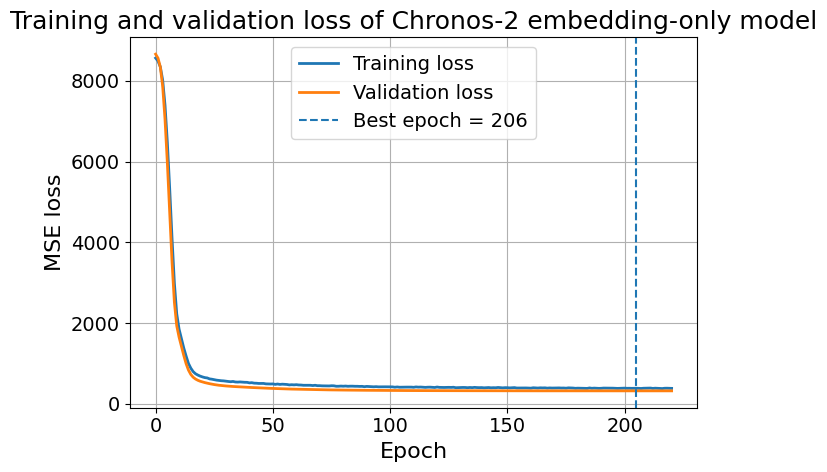

In [ ]:
# Training and validation loss

train_loss_embedding = history_chronos_embedding.history["loss"]
valid_loss_embedding = history_chronos_embedding.history["val_loss"]
best_epoch_embedding = np.argmin(valid_loss_embedding) + 1

plt.figure(figsize=(7, 5))
plt.plot(train_loss_embedding, label="Training loss", linewidth=2)
plt.plot(valid_loss_embedding, label="Validation loss", linewidth=2)
plt.axvline(
    best_epoch_embedding - 1,
    linestyle="--",
    linewidth=1.5,
    label=f"Best epoch = {best_epoch_embedding}",
)
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title(f"Training and validation loss of {model_label_embedding}"); plt.grid(True)
plt.legend(); plt.tight_layout(); plt.show()

# Ch-2 embed-only model: 10% data

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
selection_seed = 0

import time

# Set the epoch reporting interval

# Ten selected engines, five-fold engine-wise validation
# Chronos-2 embeddings are reused without another extraction.

rng = np.random.default_rng(selection_seed)
engine_ids_all = np.sort(np.unique(eng_seq))
selected_engines_embedding_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))
kfold_embedding = KFold(n_splits=5, shuffle=True, random_state=0)

results_chronos_embedding_10 = []
splits_chronos_embedding_10 = []
start_time = time.perf_counter()

print(f"Selected engines: {selected_engines_embedding_10.astype(int).tolist()}")

for fold, (train_pos, valid_pos) in enumerate(
    kfold_embedding.split(selected_engines_embedding_10), start=1
):
    fold_start = time.perf_counter()
    train_engines = selected_engines_embedding_10[train_pos]
    valid_engines = selected_engines_embedding_10[valid_pos]
    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(fold)
    model_chronos_embedding_10 = build_chronos_embedding_head(
        Z_seq.shape[1], Z_seq.shape[2]
    )
    early_stopping_embedding_10 = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_chronos_embedding_10, Z_seq[idx_train], Z_seq[idx_valid])
    training_started = time.perf_counter()
    history_embedding_10 = model_chronos_embedding_10.fit(
        Z_seq[idx_train],
        y_seq[idx_train],
        batch_size=batch_size,
        epochs=max_epochs,
        validation_data=(Z_seq[idx_valid], y_seq[idx_valid]),
        callbacks=[early_stopping_embedding_10]
        + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history_embedding_10, training_started)

    pred_final = model_chronos_embedding_10.predict(Z_test_final, verbose=0).ravel()
    rmse, score = cmapss_metrics(true_rul_final, pred_final)

    results_chronos_embedding_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history_embedding_10.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_chronos_embedding_10.append(
        {"Fold": fold, "Train": train_engines, "Validation": valid_engines}
    )

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}, Time ="
        f" {format_number((time.perf_counter() - fold_start) / 60, '.2f')} min"
    )

results_chronos_embedding_10 = pd.DataFrame(results_chronos_embedding_10)
display(results_chronos_embedding_10.round(4))

print(f"Total time = {format_number((time.perf_counter() - start_time) / 60, '.2f')} min")
print(
    "Test RMSE ="
    f" {format_number(results_chronos_embedding_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_chronos_embedding_10['Test RMSE'].std(), '.4f')}"
)
print(
    "C-MAPSS Score ="
    f" {format_number(results_chronos_embedding_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_chronos_embedding_10['C-MAPSS Score'].std(), '.2f')}"
)

Selected engines: [2, 4, 8, 18, 26, 30, 48, 59, 78, 82]
Fold 1: RMSE = 20.5177, Score = 881.61, Time = 1.04 min
Fold 2: RMSE = 21.7015, Score = 1210.85, Time = 0.76 min
Fold 3: RMSE = 20.5474, Score = 962.87, Time = 1.26 min
Fold 4: RMSE = 20.9148, Score = 938.61, Time = 0.61 min
Fold 5: RMSE = 20.9145, Score = 898.79, Time = 0.62 min


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,377,20.5177,881.6086
1,2,273,21.7015,1210.8520
2,3,466,20.5474,962.8746
3,4,214,20.9148,938.6089
4,5,212,20.9145,898.7854


Total time = 4.29 min
Test RMSE = 20.9192 ± 0.4773
C-MAPSS Score = 978.55 ± 133.76


# MLP with one cycle sensor: full data

### Functions

In [ ]:
# Purpose: build the sensor-input-only MLP RUL regression head.
# Input: n_features.
# Output: returned model.
# Used in: MLP with one cycle sensor: full data; MLP with one cycle sensor: 10% data.
def build_sensor_head(n_features):
    x_in = tf.keras.Input(shape=(n_features,))
    x = x_in

    for units in hidden_units:
        x = tf.keras.layers.Dense(units, activation=tf.nn.gelu)(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)

    y_out = tf.keras.layers.Dense(1)(x)

    model = tf.keras.Model(x_in, y_out)
    model.compile(
        optimizer=AdamW(learning_rate=learning_rate, weight_decay=weight_decay),
        loss="mse",
    )
    return model

### Preparation for the scratch sensor-only MLP experiment

In [ ]:
# User settings: change these values to repeat the experiment
sensor_max_epochs = 150  # 2000

# Settings and diagnostics for the scratch sensor-only MLP

# Purpose: print loss summary.
# Input: history, label.
# Output: updated state or displayed result; no return value.
# Used in: MLP with one cycle sensor: full data; MLP with one cycle sensor: 10% data.
def print_loss_summary(history, label):
    train = np.asarray(history.history["loss"])
    valid = np.asarray(history.history["val_loss"])
    interval = min(10, len(valid) - 1)
    previous = valid[-1 - interval]
    reduction = 100 * (previous - valid[-1]) / max(previous, 1e-12)
    print(f"\n{label}")
    print(f"Epochs: {len(valid)}, Best epoch: {np.argmin(valid) + 1}")
    print(
        f"Training loss: {format_number(train[0], '.4f')} ->"
        f" {format_number(train[-1], '.4f')}"
    )
    print(
        f"Validation loss: {format_number(valid[0], '.4f')} ->"
        f" {format_number(valid[-1], '.4f')}"
    )
    print(
        f"Validation loss reduction over last {interval} epochs:"
        f" {format_number(reduction, '.2f')}%"
    )

### MLP training and test RUL prediction

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting

import time

# Set the epoch reporting interval

# Sensor-input-only MLP
# Full data and ten-engine experiments

# Full-data experiment

engine_ids = np.unique(eng_seq)
train_engines_sensor, valid_engines_sensor = train_test_split(
    engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=0
)

idx_train = np.isin(eng_seq, train_engines_sensor)
idx_valid = np.isin(eng_seq, valid_engines_sensor)

tf.keras.utils.set_random_seed(0)

model_sensor = build_sensor_head(X_current_sensors.shape[1])

early_stopping_sensor = EarlyStopping(
    monitor="val_loss", patience=patience, restore_best_weights=True
)

start_time = time.perf_counter()

# Report the model and data before training
show_model_info(model_sensor, X_current_sensors[idx_train], X_current_sensors[idx_valid])
training_started = time.perf_counter()
history_sensor = model_sensor.fit(
    X_current_sensors[idx_train],
    y_seq[idx_train],
    batch_size=batch_size,
    epochs=sensor_max_epochs,
    validation_data=(X_current_sensors[idx_valid], y_seq[idx_valid]),
    callbacks=[early_stopping_sensor] + [training_progress(progress_interval)],
    verbose=0,
)
report_training(history_sensor, training_started)

print_loss_summary(history_sensor, "Full data")

print(
    "Training time of sensor-only head:"
    f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
)

pred_sensor_final = model_sensor.predict(X_test_sensors, verbose=0).ravel()

rmse_sensor, score_sensor = cmapss_metrics(true_rul_final, pred_sensor_final)

print(
    f"{dataName} final-cycle test RMSE of Scratch_SensorOnlyMLP ="
    f" {format_number(rmse_sensor, '.4f')}"
)
print(
    f"{dataName} final-cycle test Score of Scratch_SensorOnlyMLP ="
    f" {format_number(score_sensor, '.4f')}"
)

# MLP with one cycle sensor: 10% data

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
selection_seed = 0

import time

# Set the epoch reporting interval

# Ten-engine five-fold experiment

rng = np.random.default_rng(selection_seed)

selected_engines_sensor_10 = np.sort(rng.choice(np.unique(eng_seq), 10, replace=False))

kfold_sensor = KFold(n_splits=5, shuffle=True, random_state=0)

results_sensor_10 = []
start_time = time.perf_counter()

print(f"Selected engines: {selected_engines_sensor_10.astype(int).tolist()}")

for fold, (train_pos, valid_pos) in enumerate(
    kfold_sensor.split(selected_engines_sensor_10), start=1
):

    fold_start = time.perf_counter()

    train_engines = selected_engines_sensor_10[train_pos]
    valid_engines = selected_engines_sensor_10[valid_pos]

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    tf.keras.utils.set_random_seed(fold)

    model_sensor_10 = build_sensor_head(X_current_sensors.shape[1])

    early_stopping_sensor_10 = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(
        model_sensor_10, X_current_sensors[idx_train], X_current_sensors[idx_valid]
    )
    training_started = time.perf_counter()
    history_sensor_10 = model_sensor_10.fit(
        X_current_sensors[idx_train],
        y_seq[idx_train],
        batch_size=batch_size,
        epochs=sensor_max_epochs,
        validation_data=(X_current_sensors[idx_valid], y_seq[idx_valid]),
        callbacks=[early_stopping_sensor_10] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history_sensor_10, training_started)

    print_loss_summary(history_sensor_10, f"10% data - Fold {fold}")

    pred_final = model_sensor_10.predict(X_test_sensors, verbose=0).ravel()

    rmse, score = cmapss_metrics(true_rul_final, pred_final)

    results_sensor_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history_sensor_10.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}, Time ="
        f" {format_number((time.perf_counter() - fold_start) / 60, '.2f')} min"
    )

results_sensor_10 = pd.DataFrame(results_sensor_10)

display(results_sensor_10.round(4))

print(f"Total time = {format_number((time.perf_counter() - start_time) / 60, '.2f')} min")
print(
    f"Test RMSE = {format_number(results_sensor_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_sensor_10['Test RMSE'].std(), '.4f')}"
)
print(
    f"C-MAPSS Score = {format_number(results_sensor_10['C-MAPSS Score'].mean(), '.2f')}"
    f" ± {format_number(results_sensor_10['C-MAPSS Score'].std(), '.2f')}"
)

# MLP results from 2000-epoch trial

These results were supplied by the author from the completed Colab run. They are a reference record, not execution output from this revised notebook.

| Data | Test RMSE | C-MAPSS Score | Time (min) |
|---|---:|---:|---:|
| Full training data | 20.4509 | 923.8550 | 1.47 |
| 10% training data, mean ± sample SD | 29.6623 ± 2.1203 | 2275.78 ± 571.05 | 15.45 |

| Fold | Epochs | Best epoch | Test RMSE | C-MAPSS Score |
|---|---:|---:|---:|---:|
| 1 | 2000 | 2000 | 26.9108 | 1658.1501 |
| 2 | 2000 | 2000 | 29.3703 | 2063.5124 |
| 3 | 1829 | 1814 | 28.8355 | 1998.1945 |
| 4 | 1418 | 1403 | 32.6352 | 3135.7665 |
| 5 | 1560 | 1545 | 30.5595 | 2523.2793 |